In [1]:
from dataclasses import dataclass
import numpy as np

In [2]:
import matplotlib.pyplot as plt

def uniform_points_on_sphere(R=2, N=40):
    cos_theta = np.random.default_rng().uniform(-1, 1, N)
    sin_theta = np.sqrt(1-cos_theta**2)
    phi = np.random.default_rng().uniform(0, 2*np.pi, N)
    return R*np.array([np.cos(phi)*sin_theta, np.sin(phi)*sin_theta, cos_theta])

def plot_points_3d(points, *args):
    fig = plt.figure(figsize=plt.figaspect(0.5))
    ax = fig.add_subplot(1, 1, 1, projection='3d')
    ax.scatter(points[:,0], points[:, 1], points[:, 2])
    ax.view_init(*args)

In [3]:
@dataclass
class Detector():
    R: float = 2. # m
    """Big Sphere Radius"""
    N: int = 40 
    """Amount of PMs"""
    r: float = 0.1 # m
    """PM Radius""" 
    a: float = 0.5
    """Photon Detection Efficiency"""
    position: tuple = (0., 0., 0.)
    """Sphere Center"""

    def __post_init__(self):
        # random_positions = uniform_points_on_sphere(self.R, self.N)
        self.place_pm_on_sphere()
        self.geometry = np.vstack((np.arange(1, self.geometry.shape[1]+1, 1), self.geometry)).T # add N_channel is in [1, N] 
        if isinstance(self.position, tuple): self.position = np.asarray(self.position)
        self.geometry[:, 1:] += self.position
                
    def place_pm_on_sphere(self) -> None:
        """Create points on sphere """
        # firstly, place 10 detectors on "equator"    
        phi = np.arange(0, 2*np.pi, 2*np.pi/10)
        pos0 = self.R * np.array([np.cos(phi), np.sin(phi), np.zeros(phi.size)])
        # secondly, rotate them along X axis
        pos1 = pos0
        for alpha in range(1, self.N//10):
            pos_r = np.array([pos0[0], pos0[1]*np.cos(np.pi/(self.N//10)*alpha), pos0[2]+pos0[1]*np.sin(np.pi/(self.N//10)*alpha)])
            pos1 = np.hstack((pos1, pos_r))
        pos1[np.abs(pos1) < 1e-3] = 0
        self.geometry = np.unique(pos1.T, axis=0).T
        
    def point_is_in_pm(self, point) -> int:
        """Returns OM_ID of worked OM"""
        # check if point is on sphere
        if np.linalg.norm(point) != self.R: 
            print("Point is not on shere")
            return 0 # N_channel=0 means point is not in any channel
        pm_pos = self.geometry[:, 1:]
        distances = np.linalg.norm(pm_pos - point, axis=1)
        # check if there is any point in area of channel
        mask = distances < self.r
        return self.geometry[mask, 0] # return om_id of worked om
    
    def points_are_in_pm(self, points: np.ndarray) -> np.ndarray:
        """Returns OM_ID of worked OM"""
        points = np.asarray(points)
        # take points on sphere
        points_on_sphere = points[np.isclose(np.linalg.norm(points, axis=1), self.R)] 
        if points_on_sphere.size == 0: 
            print("No points on sphere")
            return 0 # N_channel=0 means point is not in any channel
        pm_pos = self.geometry[:, 1:]
        distances = np.linalg.norm(pm_pos[:, None, :]  - points_on_sphere[None, :, :], axis=2)
        mask = distances < self.r
        pm_idx, pt_idx = np.where(mask)
        hitted_pms = self.geometry[pm_idx, 0]
        return np.vstack(np.unique(hitted_pms, return_counts=True)).astype(np.int32).T # hits = [om_id, n_photons in it]

    def make_charge(self, hits):
        hits[:, 1] = np.random.default_rng().poisson(self.a * hits[:, 1])
        return hits

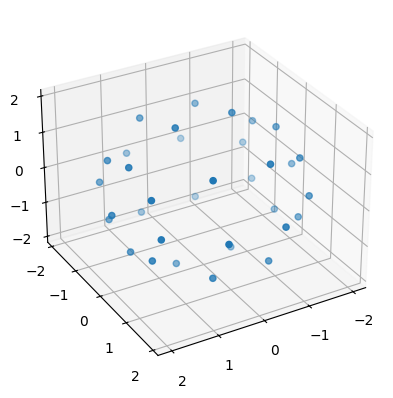

In [4]:
det = Detector(N=40, position=(0, 0, 0))
plot_points_3d(det.geometry[:, 1:], 30, 60)

In [5]:
def test_points_are_in_pm():
    det = Detector(N=40)
    pm_worked = det.points_are_in_pm([[0,0,0], det.geometry[0, 1:], [0,0,2], *det.geometry[:, 1:]]) 
    assert pm_worked.shape == (det.geometry.shape[0], 2)
    assert pm_worked[0, 1] == 2
    assert pm_worked[1:, 1].all() == 1
test_points_are_in_pm()

##### Визуализация в k3d. (Почему-то в VSCode не отображается, но в Jupyter работает исправно)

In [6]:
import k3d
plot = k3d.plot(grid_visible=True,
                camera_auto_fit=True
               )

sphere_points = k3d.points(positions=det.geometry[:, 1:],
                           point_size=2 * det.r,       
                           shader='3d',
                           color=0x33aaff
                          )
plot += sphere_points

plot.display()

Output()